# Test uploaded photos with the trained model
Run the three code cells below in order, or choose Run All. This only performs inference; it does not train, modify your photos or rerun the MIDV test set.

Photos are read from training/data/raw/passport and training/data/raw/driving_licence. Folder names are expected image-level labels. Add negative photos under training/data/raw/none if available. Detection uses the same 0.25 threshold as notebook 03, without tuning on these photos.

The table shows expected and predicted type, detector confidence, and a type match. The plots show every predicted box so you can judge localization yourself. No manual bounding-box annotations are available, so this notebook cannot calculate detection mAP or localization recall. Five photos are a small sanity check, not a reliability benchmark. Confidence is not a capture-quality score.

The MIDV evaluation produced a 20.2% negative-image false-positive rate at this threshold. More varied negatives may be needed before accepting automatic captures.


In [7]:
from pathlib import Path
import json
import torch
from ultralytics import YOLO
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from html import escape

PROJECT = Path('/home/joe/PycharmProjects/id-capture')
RAW = PROJECT / 'training/data/raw'
pointer = json.loads((PROJECT / 'training/data/midv500_yolo/latest_run.json').read_text())
BEST = Path(pointer['best'])
assert BEST.is_file(), BEST
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
CONFIDENCE = 0.25
manual_model = YOLO(str(BEST))
extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp', '.webp'}
samples = []
for expected in ('passport', 'driving_licence', 'none'):
    folder = RAW / expected
    if folder.is_dir():
        samples.extend((path, expected) for path in sorted(folder.iterdir()) if path.is_file() and path.suffix.lower() in extensions)
assert samples, 'No supported photos found in ' + str(RAW)
print('Checkpoint:', BEST)
print('Inference device:', torch.cuda.get_device_name(0) if DEVICE == 0 else 'CPU')
print('Photos:', len(samples))
for path, expected in samples:
    print(expected, ':', path.name)


Checkpoint: /home/joe/PycharmProjects/id-capture/training/runs/yolo11n_midv500_20261012_095837_074736/weights/best.pt
Inference device: NVIDIA GeForce RTX 5060 Ti
Photos: 9
passport : passport1.jpg
passport : passport2.jpg
passport : passport3.jpg
driving_licence : driving_licence1.jpg
driving_licence : driving_licence2.jpg
none : none1.jpg
none : none2.jpg
none : none3.jpg
none : none4.jpg


In [8]:
manual_rows = []
manual_predictions = []
for path, expected in samples:
    # Normalize phone EXIF rotation before inference and plotting.
    with Image.open(path) as original:
        rgb = np.asarray(ImageOps.exif_transpose(original).convert('RGB'))
    bgr = np.ascontiguousarray(rgb[..., ::-1])
    prediction = manual_model.predict(source=bgr, device=DEVICE, imgsz=640,
                                      conf=CONFIDENCE, verbose=False)[0]
    boxes = prediction.boxes
    if len(boxes):
        top = int(boxes.conf.argmax().item())
        predicted = prediction.names[int(boxes.cls[top].item())]
        confidence = f'{float(boxes.conf[top].item()):.1%}'
    else:
        predicted = 'none'
        confidence = 'N/A'
    manual_rows.append({
        'Photo': path.name, 'Expected': expected, 'Predicted': predicted,
        'Confidence': confidence, 'Type match': 'YES' if predicted == expected else 'NO',
        'Detections': len(boxes),
    })
    manual_predictions.append(prediction)

columns = list(manual_rows[0])
table = '<table><thead><tr>' + ''.join('<th>' + escape(c) + '</th>' for c in columns) + '</tr></thead><tbody>'
for row in manual_rows:
    table += '<tr>' + ''.join('<td>' + escape(str(row[c])) + '</td>' for c in columns) + '</tr>'
display(HTML(table + '</tbody></table>'))
matches = sum(row['Type match'] == 'YES' for row in manual_rows)
print(f'Top detection type matches: {matches}/{len(manual_rows)} photos.')
print('Inspect the boxes below: a type match alone does not confirm correct localization.')


Photo,Expected,Predicted,Confidence,Type match,Detections
passport1.jpg,passport,passport,89.1%,YES,1
passport2.jpg,passport,passport,87.9%,YES,1
passport3.jpg,passport,passport,70.0%,YES,1
driving_licence1.jpg,driving_licence,driving_licence,89.1%,YES,1
driving_licence2.jpg,driving_licence,driving_licence,77.1%,YES,1
none1.jpg,none,none,N/A,YES,0
none2.jpg,none,none,N/A,YES,0
none3.jpg,none,none,N/A,YES,0
none4.jpg,none,none,N/A,YES,0


Top detection type matches: 9/9 photos.
Inspect the boxes below: a type match alone does not confirm correct localization.


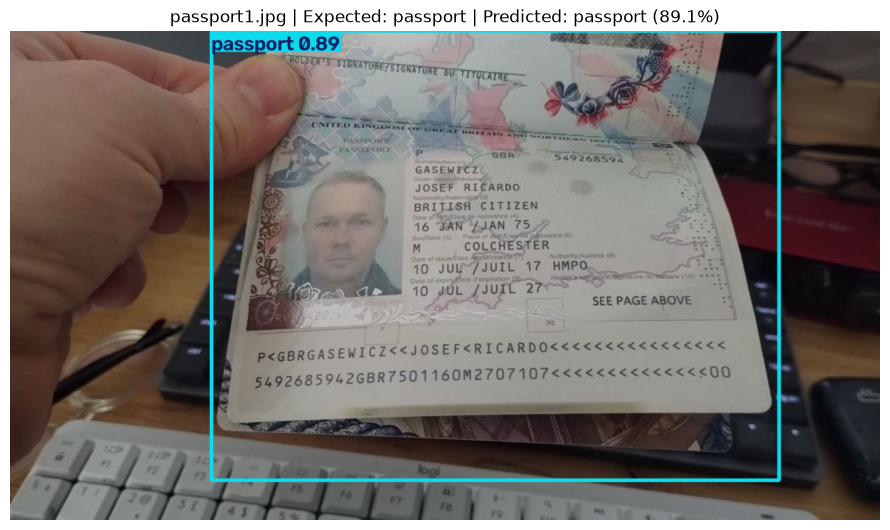

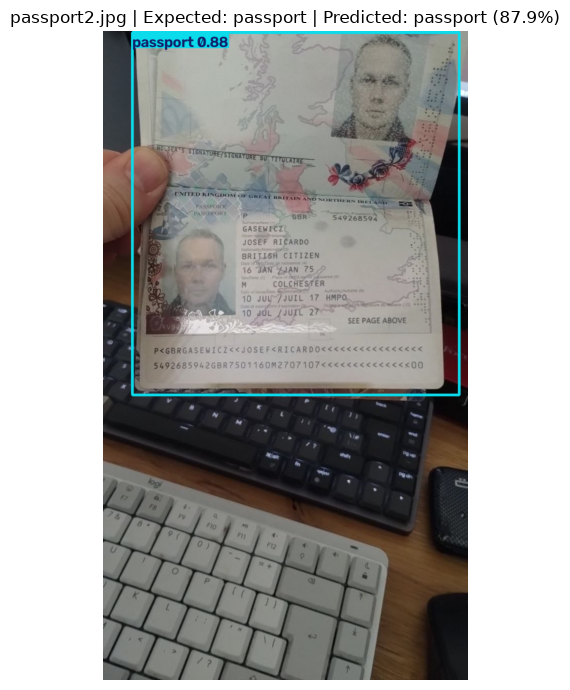

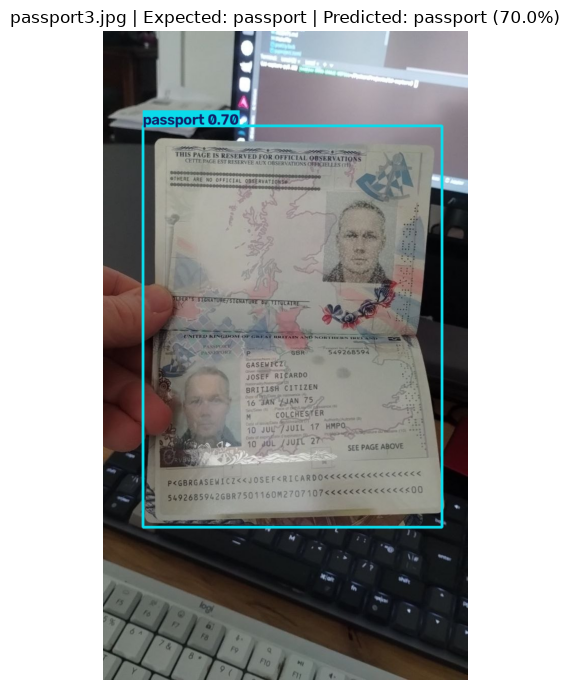

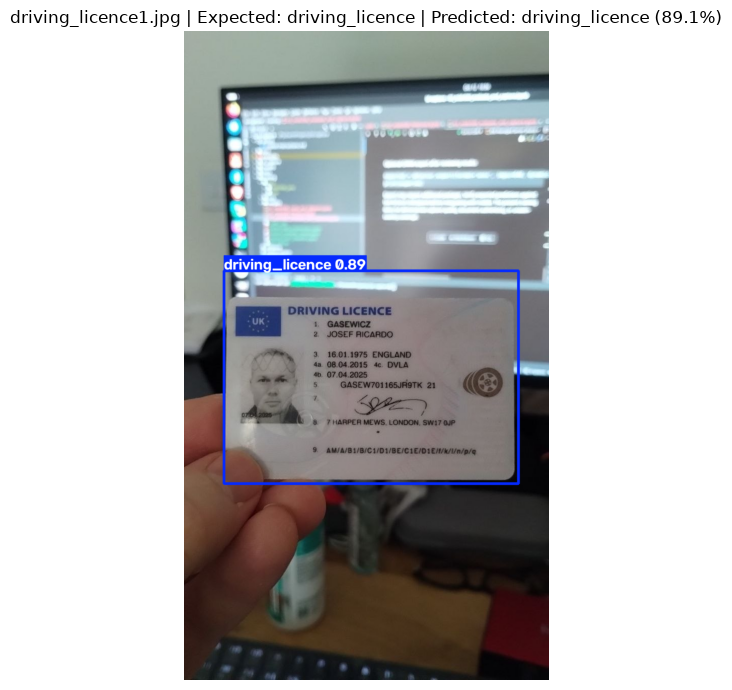

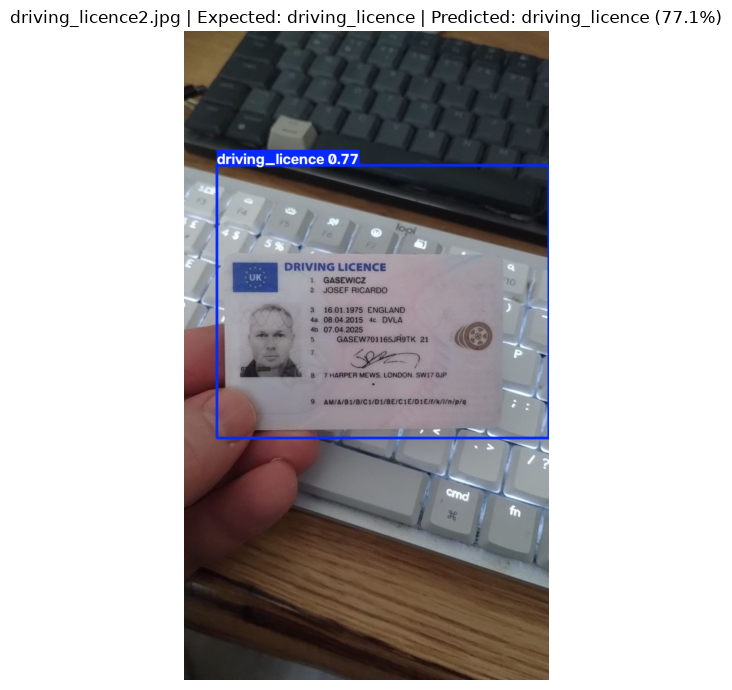

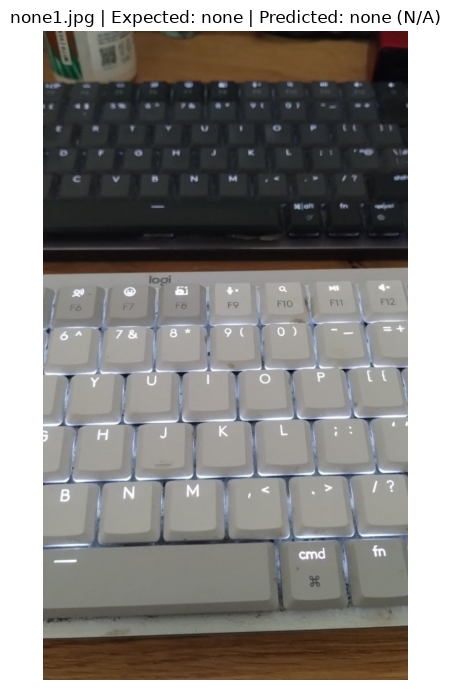

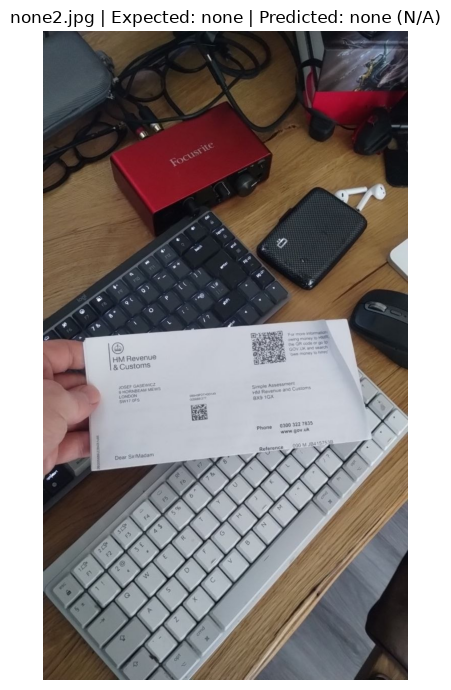

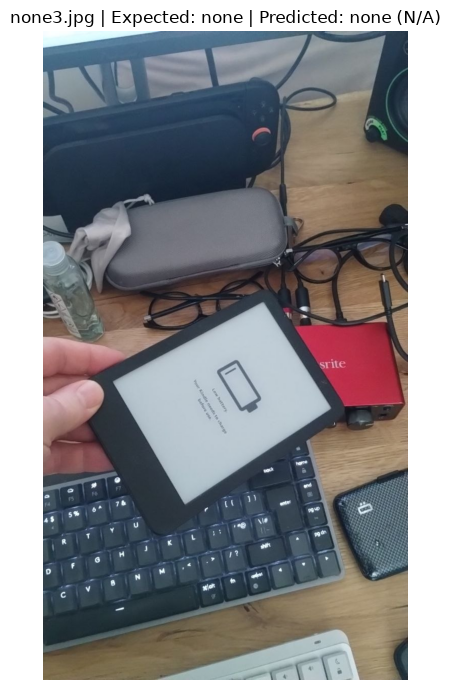

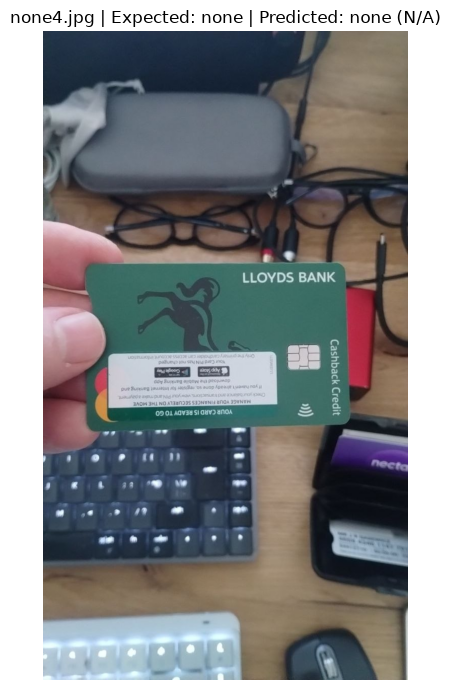

In [9]:
for (path, expected), row, prediction in zip(samples, manual_rows, manual_predictions):
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(prediction.plot()[..., ::-1])
    ax.set_title(f'{path.name} | Expected: {expected} | Predicted: {row["Predicted"]} ({row["Confidence"]})')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
